In [109]:
import pandas as pd

df = pd.read_csv("dataset.csv")

df.head()

,id,vehicle_type,latitude,longitude,timestamp
0,64,3,64.8924,16.4665,2025-12-09 19:26:55
1,657,3,64.8934,16.4681,2025-12-09 21:14:25
2,536,3,64.8922,16.4679,2025-12-09 21:08:41
3,216,3,64.8926,16.4661,2025-12-09 20:00:01
4,156,3,64.9084,16.4446,2025-12-09 21:14:37


In [110]:
df_1 = pd.DataFrame({
    "subtaskID": [1],
    "Value1": len(df.id.unique()),
    "Value2": len(df.vehicle_type.unique()),
})

df_1

,subtaskID,Value1,Value2
0,1,663,4


In [111]:
ids = df.id.unique()

feature1 = []
feature2 = []

for idx in ids:
    feature1.append(df[df.id == idx].longitude.mean())
    feature2.append(df[df.id == idx].latitude.mean())

df_test = pd.DataFrame({
    "id": ids,
    "latitude": feature2,
    "longitude": feature1
})

X = df_test[['latitude', 'longitude']]

X.head()

,latitude,longitude
0,64.896512,16.450061
1,64.909206,16.430968
2,64.890892,16.448587
3,64.892319,16.459283
4,64.886424,16.433859


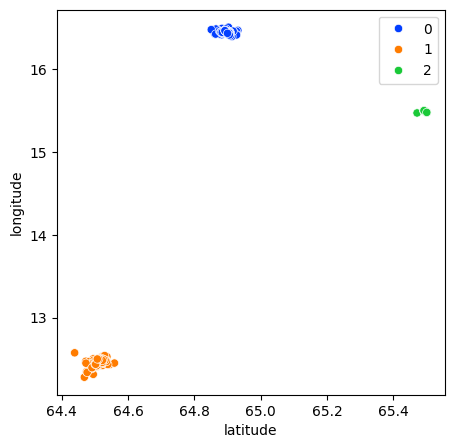

In [112]:
import matplotlib.pyplot as plt # se vad foarte clar cele 3 orase pe mean lat si long
import seaborn as sns

from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=43)
labels = kmeans.fit_predict(X)

plt.figure(figsize=(5, 5))
sns.scatterplot(x='latitude', y='longitude', data=df_test, hue=labels, palette='bright')
plt.show()

In [113]:
df_2 = pd.DataFrame({
    "subtaskID": 2,
    "Value1": ids,
    "Value2": labels,
})

df_2.head()

,subtaskID,Value1,Value2
0,2,64,0
1,2,657,0
2,2,536,0
3,2,216,0
4,2,156,0


In [131]:
df_nou = df[df.vehicle_type == 10]

df_nou['Hour'] = df_nou['timestamp'].map(lambda x : int(str(x).split()[1].split(':')[0]))

df_nou = df_nou[(df_nou.Hour >= 22) | (df_nou.Hour <= 6)]
df_nou = df_nou.groupby('id')[['latitude', 'longitude']].median().reset_index()

X = df_nou[['latitude', 'longitude']]

df_nou.head()

C:\Users\Ilie-Goga\AppData\Local\Temp\ipykernel_19568\3056473539.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_nou['Hour'] = df_nou['timestamp'].map(lambda x : int(str(x).split()[1].split(':')[0]))


,id,latitude,longitude
0,10,64.9050,16.4375
1,13,64.9050,16.4391
2,43,64.9050,16.4383
3,53,64.9050,16.4381
4,65,64.9053,16.4379


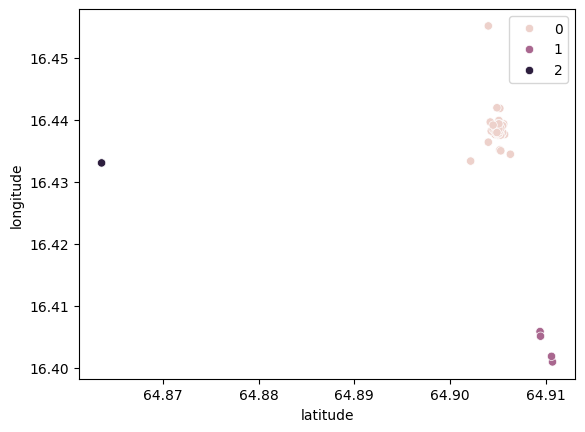

In [132]:
#ne uitam la clusteruri le clasificam si dupa facem media pt fiecare cluster
kmeans = KMeans(n_clusters=3, random_state=43)
labels = kmeans.fit_predict(X)
df_nou['cluster'] = labels
sns.scatterplot(x='latitude', y='longitude', data=df_nou, hue=labels)
plt.show()

In [133]:
mean_longs = []
mean_lats = []

for cluster in range(3):
    mean_longs.append(df_nou[df_nou.cluster==cluster].longitude.median())
    mean_lats.append(df_nou[df_nou.cluster==cluster].latitude.median())

In [134]:
df_3 = pd.DataFrame({
    "subtaskID": 3,
    "Value1": mean_lats,
    "Value2": mean_longs,
})
df_3 = df_3.sort_values("Value1")

df_3.head()

,subtaskID,Value1,Value2
2,3,64.863600,16.433000
0,3,64.905100,16.438300
1,3,64.910025,16.403425


In [135]:
submission = pd.concat([df_1, df_2, df_3])
submission

,subtaskID,Value1,Value2
0,1,663.000000,4.000000
0,2,64.000000,0.000000
1,2,657.000000,0.000000
2,2,536.000000,0.000000
3,2,216.000000,0.000000
...,...,...,...
661,2,67.000000,0.000000
662,2,250.000000,0.000000
2,3,64.863600,16.433000
0,3,64.905100,16.438300


In [136]:
submission.to_csv("submission.csv", index=False)